# SWOT KaRIn wave height from the cloud

The KaRIn interferometer of SWOT (CNES/NASA, 2022) measures two **50 km wide swaths of 2 km
pixels**, 10-60 km either side of the track, every 21 days. Its significant wave height
(`swh_karin`) gives a 2D picture of the sea state up to a few km from the coast, where
nadir altimeters fail. It is a young product: use the quality flag, stay >= 2 km from the
coast and take the median of the pixels around a point.

The store holds the ocean pixels of the L2 WindWave product (version D) since 2023-03, in
monthly blocks sorted by 1x1 degree cell, and is appended every month.

Requirements: `bluemath-tk` (with `bluemath_tk.waves.altimetry`), `xarray`, `zarr>=3`, `fsspec`, `aiohttp`, `matplotlib`, `cartopy`. The stores are read over HTTP: only the chunks needed are downloaded.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from bluemath_tk.core.metrics import compute_metrics
from bluemath_tk.waves.altimetry import open_altimeter, altimeter_near, altimeter_passes, collocate

# Public GeoOcean Zarr stores. On the GeoOcean cluster use "http://geocean01.sci.unican.es/zarr" (faster).
BASE = "https://geoocean.unican.es/zarr"
IMOS_URL = f"{BASE}/IMOS/imos_altimeter_dm00.zarr"
SWOT_URL = f"{BASE}/SWOT/swot_karin_windwave.zarr"
WHACS_URL = f"{BASE}/CSIRO/whacs_global_smc_1h_2020_2023.zarr"

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.grid": True, "grid.color": "#e4e3df", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

LON, LAT = -3.8, 43.7  # Cantabrian Sea, ~20 km off Santander

In [2]:
swot = open_altimeter(SWOT_URL)
for key in ("summary", "usage", "time_coverage_start", "time_coverage_end"):
    print(f"{key}: {swot.attrs[key]}\n")
swot

summary: Significant wave height (swh_karin), wind speed and backscatter from the KaRIn interferometer of SWOT (CNES/NASA L2 low-rate WindWave product, version D): two 50 km swaths of 2 km pixels, 10-60 km either side of the track, ocean pixels only, all quality classes, from 2023-03, appended every month. One version per pass; values as in the source files; depth from GEBCO 2026.

usage: One dimension obs, made of one block per calendar month (month of the pass start), each sorted by 1x1 degree cell and then by time; cell_start and cell_count on (month, lat_cell = floor(latitude), lon_cell = floor(longitude), longitudes 0-360) give the slice of obs of each cell and month, so a cell is one slice per month. Recommended: swh_karin_qual == 0, distance_to_coast >= 2 km and the median of the pixels within ~5 km of a point, keeping zeros in the median (0 marks a failed retrieval in calm seas). KaRIn Hs is a young product: in a North Sea validation it was unbiased above 2 m and biased high by

<xarray.Dataset> Size: 755GB
Dimensions:                (month: 43, lat_cell: 180, lon_cell: 360,
                            obs: 12172497938)
Coordinates:
  * month                  (month) datetime64[ns] 344B 2023-03-01 ... 2026-09-01
  * lat_cell               (lat_cell) int16 360B -90 -89 -88 -87 ... 86 87 88 89
  * lon_cell               (lon_cell) int16 720B 0 1 2 3 4 ... 356 357 358 359
    latitude               (obs) float64 97GB dask.array<chunksize=(32768,), meta=np.ndarray>
    longitude              (obs) float64 97GB dask.array<chunksize=(32768,), meta=np.ndarray>
    time                   (obs) datetime64[ns] 97GB dask.array<chunksize=(32768,), meta=np.ndarray>
Dimensions without coordinates: obs
Data variables: (12/16)
    cell_count             (month, lat_cell, lon_cell) int32 11MB 0 0 0 ... 0 0
    cell_start             (month, lat_cell, lon_cell) int64 22MB 0 ... 12172...
    crid                   (obs) uint8 12GB dask.array<chunksize=(32768,), meta=np.ndarray>
    cycle                  (obs) uint16 24GB dask.array<chunksize=(32768,), meta=np.ndarray>
    depth                  (obs) int16 24GB dask.array<chunksize=(32768,), meta=np.ndarray>
    distance_to_coast      (obs) float32 49GB dask.array<chunksize=(32768,), meta=np.ndarray>
    ...                     ...
    sig0_karin             (obs) float32 49GB dask.array<chunksize=(32768,), meta=np.ndarray>
    swh_karin              (obs) float32 49GB dask.array<chunksize=(32768,), meta=np.ndarray>
    swh_karin_qual         (obs) uint32 49GB dask.array<chunksize=(32768,), meta=np.ndarray>
    swh_karin_uncert       (obs) float32 49GB dask.array<chunksize=(32768,), meta=np.ndarray>
    wind_speed_karin       (obs) float32 49GB dask.array<chunksize=(32768,), meta=np.ndarray>
    wind_speed_karin_qual  (obs) uint32 49GB dask.array<chunksize=(32768,), meta=np.ndarray>
Attributes: (12/14)
    title:                SWOT KaRIn significant wave height and wind speed (...
    summary:              Significant wave height (swh_karin), wind speed and...
    usage:                One dimension obs, made of one block per calendar m...
    source:               SWOT Level 2 KaRIn Low Rate Sea Surface Height Data...
    source_url:           https://podaac.jpl.nasa.gov/SWOT
    references:           doi:10.5067/SWOT-SSH-D; GEBCO Compilation Group (20...
    ...                   ...
    creator_name:         GeoOcean, Universidad de Cantabria
    creator_url:          https://geoocean.unican.es
    time_coverage_start:  2023-03-01T00:00:00
    time_coverage_end:    2026-09-30T23:59:59
    date_modified:        2026-10-27T16:47:18Z
    Conventions:          CF-1.8

## One pass as an image

Read the pixels of a box for one month (one slice per cell and month), then plot the pass
with most pixels. Pixels with a quality flag other than 0 are shown apart.

In [3]:
def read_box(ds, lon0, lon1, lat0, lat1, month=None, variables=None):
    """Observations of every 1x1 cell of a box (longitudes -180..180), optionally one month."""
    index = ds[["cell_start", "cell_count"]]
    if month is not None:
        index = index.sel(month=month)
    parts = []
    for la in range(int(np.floor(lat0)), int(np.floor(lat1)) + 1):
        for lo in range(int(np.floor(lon0)), int(np.floor(lon1)) + 1):
            cell = index.sel(lat_cell=la, lon_cell=lo % 360)
            for s, c in zip(np.atleast_1d(cell.cell_start.values), np.atleast_1d(cell.cell_count.values)):
                if c:
                    parts.append(ds[variables].isel(obs=slice(int(s), int(s + c))) if variables else ds.isel(obs=slice(int(s), int(s + c))))
    out = xr.concat(parts, "obs").load().to_dataframe().reset_index(drop=True)
    out["lon"] = (out.longitude + 180) % 360 - 180
    return out

box = (-6.0, -1.0, 43.0, 46.0)  # Bay of Biscay
pixels = read_box(swot, *box, month="2024-01-01",
                  variables=["time", "latitude", "longitude", "swh_karin", "swh_karin_qual", "cycle", "pass", "pixel"])
best = pixels.groupby(["cycle", "pass"]).size().idxmax()
one = pixels[(pixels.cycle == best[0]) & (pixels["pass"] == best[1])]
print(f"{len(pixels):,} pixels in the box in 2024-01; pass {best} has {len(one):,}, {one.time.min():%Y-%m-%d %H:%M}")

132,423 pixels in the box in 2024-01; pass (np.uint16(9), np.uint16(376)) has 11,882, 2024-01-17 13:18


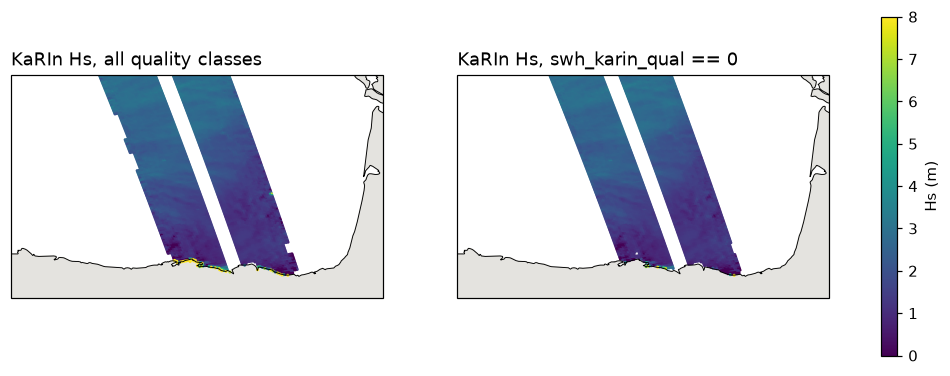

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, (title, sel) in zip(axes, [("all quality classes", one), ("swh_karin_qual == 0", one[one.swh_karin_qual == 0])]):
    ax.set_extent([box[0], box[1], box[2], box[3]])
    ax.add_feature(cfeature.LAND.with_scale("10m"), color="#e4e3df", zorder=0)
    ax.coastlines("10m", lw=0.6)
    sc = ax.scatter(sel.lon, sel.latitude, c=sel.swh_karin, s=1, cmap="viridis", vmin=0, vmax=8,
                    transform=ccrs.PlateCarree())
    ax.set_title(f"KaRIn Hs, {title}", loc="left")
plt.colorbar(sc, ax=axes, label="Hs (m)", shrink=0.8)
plt.show()

## Time series at a point

The pixels within 5 km of the point, >= 2 km from the coast, quality 0: their median per
pass is the reading that matched coastal buoys best (bias ~0 above 2 m, +0.2-0.3 m below 1 m).

3,784 pixels, 200 passes


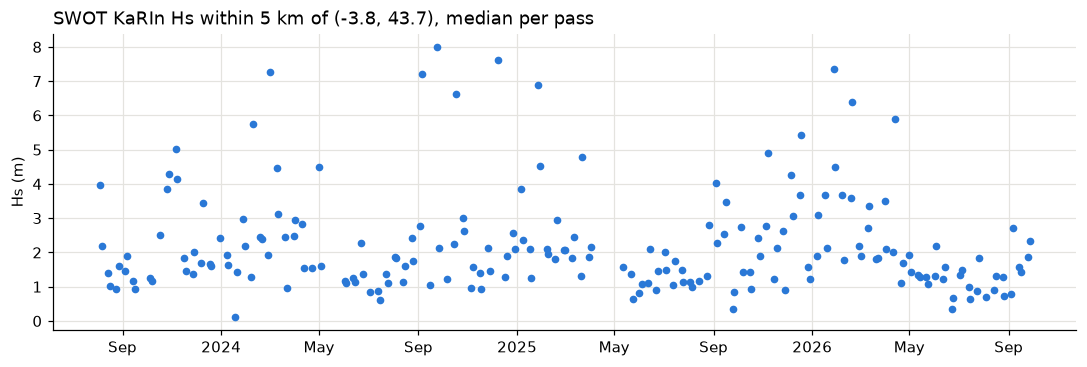

In [5]:
obs = altimeter_near(swot, LON, LAT, radius_km=5, min_dist2coast=2)
passes = altimeter_passes(obs)
print(f"{len(obs):,} pixels, {len(passes)} passes")
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(passes.index, passes.hs, "o", color=BLUE, ms=4)
ax.set_ylabel("Hs (m)")
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_title(f"SWOT KaRIn Hs within 5 km of ({LON}, {LAT}), median per pass", loc="left")
plt.show()

## KaRIn against the SWOT nadir altimeter

SWOT also carries a classic nadir altimeter, in the IMOS store (satellite `SWOT`). It
measures the line between the two swaths at the same instant, so the inner edge of the
swaths (pixels <= 20 km from the track) and the nadir Hs of the same second are compared,
without buoys.

In [6]:
imos = open_altimeter(IMOS_URL)
names = np.array(imos.satellite.attrs["flag_meanings"].split())
nadir = read_box(imos, *box, variables=["time", "latitude", "longitude", "hs", "flag", "satellite"])
nadir = nadir[(names[nadir.satellite] == "SWOT") & nadir.flag.isin([1, 2])]
nadir = nadir[(nadir.time >= "2024-01-01") & (nadir.time < "2024-04-01")].sort_values("time")

karin = pd.concat([read_box(swot, *box, month=m, variables=["time", "swh_karin", "swh_karin_qual", "pixel"])
                   for m in ("2024-01-01", "2024-02-01", "2024-03-01")])
inner = karin[(karin.swh_karin_qual == 0) & ((karin.pixel.astype(int) - 34).abs() <= 10)]
lines = inner.groupby("time").swh_karin.median().rename("karin").reset_index()  # one value per KaRIn line

pairs = pd.merge_asof(nadir[["time", "hs"]], lines.sort_values("time"), on="time",
                      tolerance=pd.Timedelta("1s"), direction="nearest").dropna()
print(f"{len(pairs):,} nadir points with KaRIn inner-swath pixels in the same second")
compute_metrics(pairs.hs, pairs.karin, ["bias", "rmse", "si", "r"])

1,555 nadir points with KaRIn inner-swath pixels in the same second


{'n': 1555,
 'bias': 0.07886495118739137,
 'rmse': 0.26868623549476617,
 'si': 0.09166706947400462,
 'r': 0.9732244815099328}

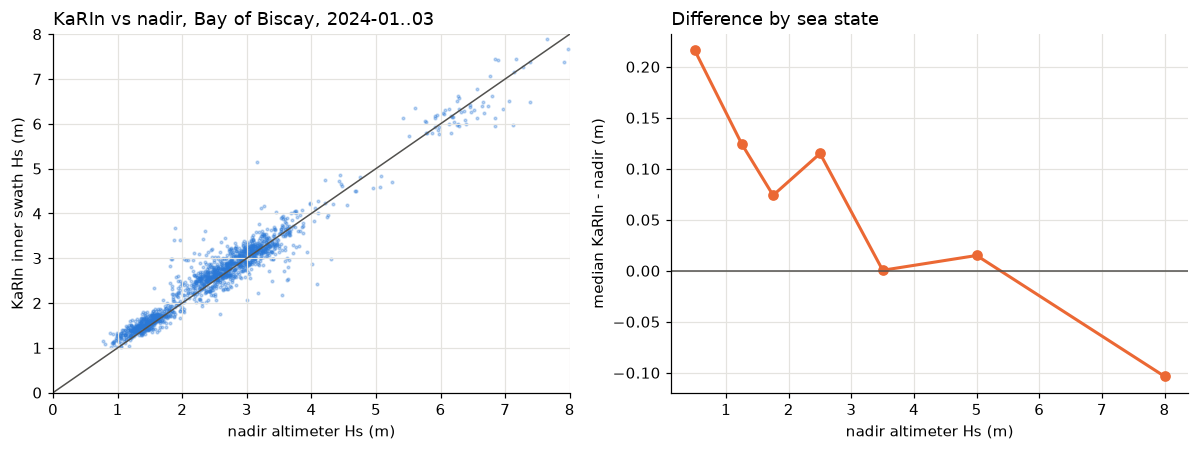

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(pairs.hs, pairs.karin, s=3, color=BLUE, alpha=0.3)
axes[0].plot([0, 8], [0, 8], color=GREY, lw=1)
axes[0].set(xlabel="nadir altimeter Hs (m)", ylabel="KaRIn inner swath Hs (m)", xlim=(0, 8), ylim=(0, 8))
axes[0].set_title("KaRIn vs nadir, Bay of Biscay, 2024-01..03", loc="left")
bins = pd.cut(pairs.hs, [0, 1, 1.5, 2, 3, 4, 6, 10])
bias = (pairs.karin - pairs.hs).groupby(bins, observed=True).median()
axes[1].plot([b.mid for b in bias.index], bias.values, "o-", color=ORANGE, lw=2)
axes[1].axhline(0, color=GREY, lw=1)
axes[1].set(xlabel="nadir altimeter Hs (m)", ylabel="median KaRIn - nadir (m)")
axes[1].set_title("Difference by sea state", loc="left")
plt.tight_layout()
plt.show()

## Notes

- `swh_karin == 0` marks a failed retrieval in calm seas: keep it in the median of a patch,
  do not filter it pixel by pixel.
- Hs below ~1 m is biased high; the far edge of the swath (50-60 km) is noisier.
- Cite doi:10.5067/SWOT-SSH-D (see the store `license`).